# Palavras da Bíblia: what the counts show

Word counts of the Portuguese Bible, *Almeida Revista e Atualizada* (1993): 592,643 words, 30,127 distinct, 66 books. The translation is protected, so the dataset has counts and short quoted excerpts, not the text.

Dataset: [Kaggle](https://www.kaggle.com/datasets/caiquedourado/palavras-da-biblia) · [GitHub](https://github.com/CaiqueDourado/palavras-da-biblia)

In [1]:
from pathlib import Path
import json, math
import pandas as pd
import matplotlib.pyplot as plt

KAGGLE = next((p.parent for p in Path("/kaggle/input").glob("**/palavras.csv")), None)
DATA = KAGGLE or Path("../data")
read = lambda name: pd.read_csv(DATA / name, keep_default_na=False)   # "nan" would become NaN otherwise
palavras, livros, por_livro = read("palavras.csv"), read("livros.csv"), read("palavras_por_livro.csv")
caract, contextos = read("palavras_caracteristicas.csv"), read("contextos.csv")
stats = json.loads((DATA / "stats.json").read_text(encoding="utf-8"))
{k: v for k, v in stats.items() if k != "top10_conteudo"}

{'traducao': 'Almeida Revista e Atualizada, 1993 (versao_id 1 no banco do autor)',
 'versiculos': 31104,
 'livros': 66,
 'capitulos': 1189,
 'palavras': 592643,
 'vocabulario': 30127,
 'palavras_at': 454624,
 'palavras_nt': 138019,
 'hapax': 13268,
 'funcionais': 309,
 'ocorrencias_funcionais': 289560,
 'contextos': 114,
 'palavras_com_contexto': 38}

## The most frequent words

Function words (de, que, os…) are flagged in `funcional`; leaving them out shows the vocabulary of the text.

,palavra,ocorrencias,versiculos,livros,ocorrencias_at,ocorrencias_nt
6,senhor,8046,6837,61,7327,719
15,deus,4438,3892,64,3103,1335
24,terra,2907,2578,55,2632,275
26,filhos,2831,2374,58,2673,158
29,israel,2544,2296,47,2477,67
31,rei,2437,1915,44,2344,93
33,disse,2402,2312,49,1939,463
34,filho,2396,1806,60,1970,426
41,casa,2006,1748,56,1765,241
44,povo,1893,1718,53,1705,188


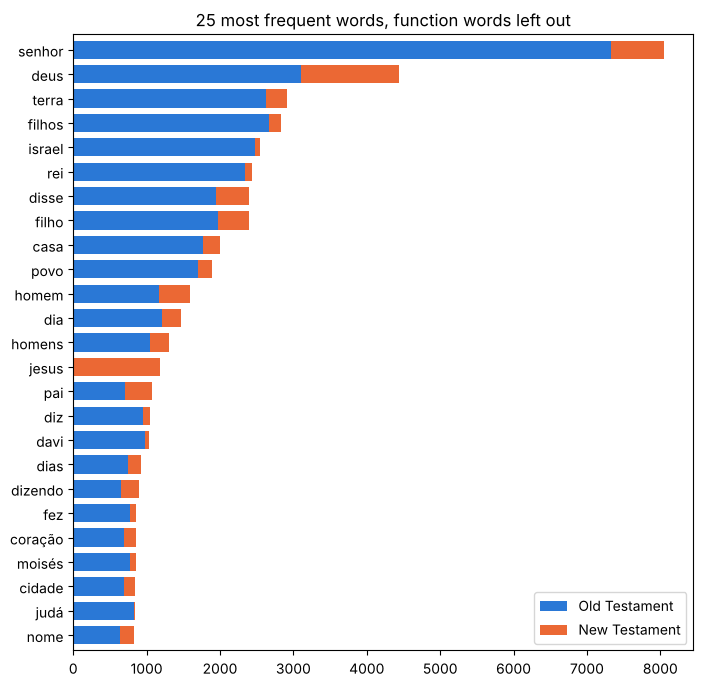

In [2]:
top = palavras[~palavras.funcional].head(25)
ax = top.iloc[::-1].plot.barh(x="palavra", y=["ocorrencias_at", "ocorrencias_nt"], stacked=True, figsize=(8, 8),
                              color=["#2a78d6", "#eb6834"], width=0.75)
ax.legend(["Old Testament", "New Testament"]); ax.set_ylabel(""); ax.set_title("25 most frequent words, function words left out")
top[["palavra", "ocorrencias", "versiculos", "livros", "ocorrencias_at", "ocorrencias_nt"]].head(10)

## Half of the text is function words

309 function words = 48.9% of all words
top 100 words = 48.4%
13,268 words appear once (44% of the vocabulary)


,palavra,ocorrencias
26721,povo-contra-quem-o-senhor-está-irado-para-sempre,1
16165,rápido-despojo-presa-segura,2
29254,terror-por-todos-os-lados,1
29250,terra-de-perversidade,1
18118,apodrecer-se-lhes-ão,1


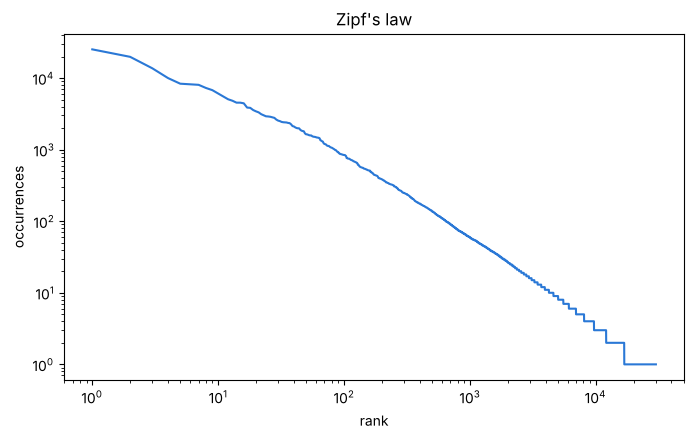

In [3]:
f = palavras[palavras.funcional]
print(f"{len(f)} function words = {f.ocorrencias.sum() / palavras.ocorrencias.sum():.1%} of all words")
print(f"top 100 words = {palavras.head(100).ocorrencias.sum() / palavras.ocorrencias.sum():.1%}")
print(f"{(palavras.ocorrencias == 1).sum():,} words appear once ({(palavras.ocorrencias == 1).mean():.0%} of the vocabulary)")
ax = palavras.ocorrencias.reset_index(drop=True).rename(lambda i: i + 1).plot(loglog=True, figsize=(8, 4.5), color="#2a78d6")
ax.set_xlabel("rank"); ax.set_ylabel("occurrences"); ax.set_title("Zipf's law")
palavras.loc[palavras.palavra.str.len().nlargest(5).index, ["palavra", "ocorrencias"]]

## Words of one Testament

The Old Testament is 3.3 times longer, so compare rates per 10,000 words.

In [4]:
at, nt = stats["palavras_at"], stats["palavras_nt"]
d = palavras[~palavras.funcional & (palavras.ocorrencias >= 80)].copy()
d["por_10mil_at"] = (d.ocorrencias_at / at * 1e4).round(1)
d["por_10mil_nt"] = (d.ocorrencias_nt / nt * 1e4).round(1)
d["log2_nt_sobre_at"] = [round(math.log2((n + 1) / nt) - math.log2((a + 1) / at), 2) for a, n in zip(d.ocorrencias_at, d.ocorrencias_nt)]
cols = ["palavra", "ocorrencias_at", "ocorrencias_nt", "por_10mil_at", "por_10mil_nt"]
pd.concat({"more in the OT": d.nsmallest(10, "log2_nt_sobre_at")[cols].reset_index(drop=True),
           "more in the NT": d.nlargest(10, "log2_nt_sobre_at")[cols].reset_index(drop=True)}, axis=1)

more in the OT                                                          \
         palavra ocorrencias_at ocorrencias_nt por_10mil_at por_10mil_nt   
0      príncipes            315              0          6.9          0.0   
1          tenda            268              0          5.9          0.0   
2      filisteus            247              0          5.4          0.0   
3       famílias            238              0          5.2          0.0   
4     holocausto            200              0          4.4          0.0   
5           saul            399              1          8.8          0.1   
6       manjares            154              0          3.4          0.0   
7      moradores            151              0          3.3          0.0   
8          joabe            148              0          3.3          0.0   
9        assíria            142              0          3.1          0.0   

  more in the NT                                                          
         palavra ocorrencias_at ocorrencias_nt por_10mil_at por_10mil_nt  
0          jesus              0           1180          0.0         85.5  
1         cristo              0            532          0.0         38.5  
2          paulo              0            173          0.0         12.5  
3          pedro              0            163          0.0         11.8  
4           joão              0            135          0.0          9.8  
5             fé              1            248          0.0         18.0  
6      evangelho              0            102          0.0          7.4  
7       fariseus              0             86          0.0          6.2  
8     discípulos             12            234          0.3         17.0  
9         mestre              8             72          0.2          5.2

In [5]:
palavras.set_index("palavra").loc[["fé", "graça", "amor", "paz", "pecado", "espírito", "verdade", "besta"],
    ["ocorrencias_at", "ocorrencias_nt", "livros"]]

,ocorrencias_at,ocorrencias_nt,livros
palavra,,,
fé,1,248,25
graça,49,141,38
amor,132,136,46
paz,222,95,55
pecado,271,102,38
espírito,222,347,52
verdade,130,253,47
besta,1,37,2


## Where a word lives

Counts per book and the quoted excerpts.

In [6]:
def onde(palavra, n=8):
    livros_da_palavra = por_livro.query("palavra == @palavra").nlargest(n, "ocorrencias")[["livro", "ocorrencias"]]
    display(livros_da_palavra.reset_index(drop=True))
    for r in contextos.query("palavra == @palavra").itertuples():
        print(f"{r.referencia:>22}  {r.trecho}")

onde("fé")

,livro,ocorrencias
0,Romanos,39
1,Hebreus,33
2,Gálatas,21
3,I Timóteo,18
4,Tiago,16
5,Atos,15
6,Mateus,14
7,Lucas,12


         Habacuque 2:4  … justo viverá pela sua fé.
         Romanos 14:22  A fé que tens, tem-na para …
         I Timóteo 5:8  … casa, tem negado a fé e é pior do …


In [7]:
onde("preguiçoso")

,livro,ocorrencias
0,Provérbios,15


        Provérbios 6:6  … com a formiga, ó preguiçoso, considera os seus caminhos …
      Provérbios 15:19  O caminho do preguiçoso é como que cercado …
      Provérbios 24:30  Passei pelo campo do preguiçoso e junto à vinha …


## One word per book

The word each book uses far more than the rest of the Bible: log2 of its rate in the book over its rate in the other 65 books.

In [8]:
first = caract[caract.posicao == 1].merge(livros[["livro", "testamento"]], on="livro")
first[["livro", "testamento", "palavra", "ocorrencias", "fora_do_livro", "indice"]].head(66)

,livro,testamento,palavra,ocorrencias,fora_do_livro,indice
0,Gênesis,AT,labão,56,0,11.16
1,Êxodo,AT,retorcido,21,0,10.01
2,Levítico,AT,examinará,22,0,10.57
3,Números,AT,décimas,15,0,9.52
4,Deuteronômio,AT,emprestarás,7,0,8.71
...,...,...,...,...,...,...
61,I João,NT,amamos,4,0,11.39
62,II João,NT,verdade,5,378,5.17
63,III João,NT,amado,4,81,7.04
64,Judas,NT,amados,4,37,7.05


## The size of each book

,ordem,posicao_no_testamento,livro,testamento,capitulos,versiculos,palavras,vocabulario,palavras_por_versiculo
18,19,19,Salmos,AT,150,2461,32627,5376,13.3
22,23,23,Isaías,AT,66,1292,28122,5361,21.8
23,24,24,Jeremias,AT,52,1364,32039,4679,23.5
0,1,1,Gênesis,AT,50,1533,27828,4103,18.2
41,42,3,Lucas,NT,24,1151,18780,3964,16.3


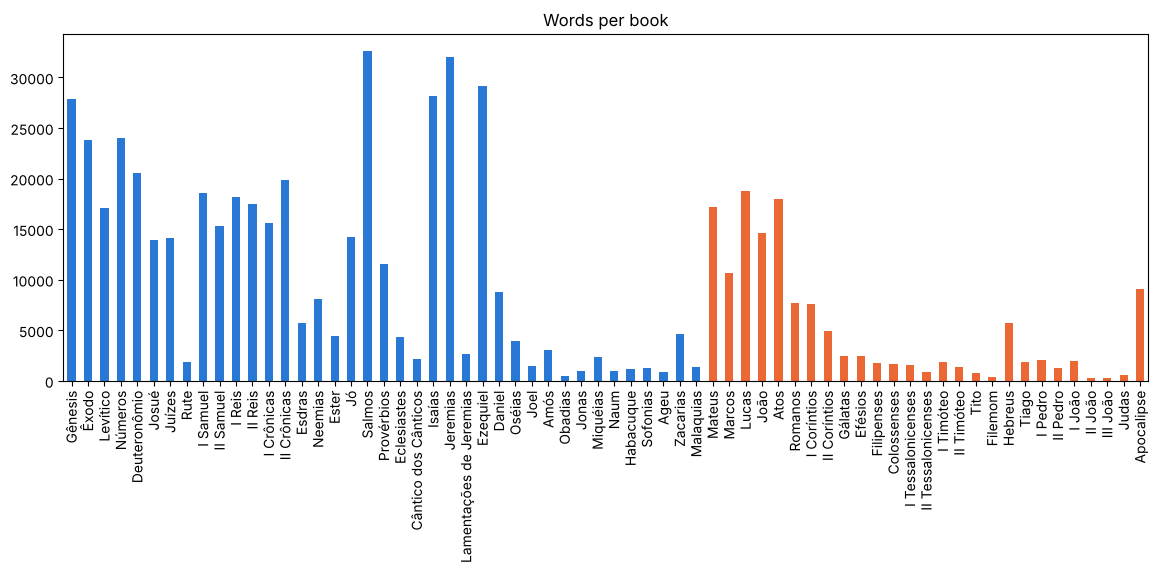

In [9]:
ax = livros.plot.bar(x="livro", y="palavras", figsize=(14, 4.5), legend=False,
                    color=["#2a78d6" if t == "AT" else "#eb6834" for t in livros.testamento])
ax.set_xlabel(""); ax.set_title("Words per book")
livros.assign(palavras_por_versiculo=(livros.palavras / livros.versiculos).round(1)).nlargest(5, "vocabulario")